# Figure 2 — Distinct perturbation programs converge on failed endothelial differentiation

This notebook reproduces panels **a, b, d, e, and f** and intentionally omits schematic panel c.

- **Panels a–b:** read the attached cNMF workbook from `data/figure_02/cNMF_50_0_2_032526_6co.xlsx` by repository-relative path.
- **Panel b:** retains the Day 3 EC-output column and uses all 120 controls (60 non-targeting plus 60 safe-targeting), guide-level Welch tests, and BH correction across 297 targets.
- **Panel d:** uses the same 120 negative-control guides. For each control guide, cells carrying any KDR, PLCG1, PRKCD, or ETV2 guide are excluded before its D3 EC percentage is calculated. Welch tests are BH-adjusted across the four displayed genes.
- **Panel e:** reuses the recovered plotnine UMAP style and color scale.
- **Panel f:** directly ports the recovered carrier-seeded plotnine notebook, including its same-day 300-neighbor scoring and red/white/blue faceted UMAP renderer.

All computational panels in this notebook are rendered with **plotnine**.


In [ ]:
# Repository-path bootstrap for local support modules.
from pathlib import Path
import sys


def _find_repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "src" / "cc_perturbseq").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate the repository root containing "
        "src/cc_perturbseq. Run this notebook from within the "
        "cc-perturbseq-manuscript-analysis checkout."
    )


REPO_ROOT = _find_repo_root()
for _support_path in (REPO_ROOT, REPO_ROOT / "src"):
    _support_path_text = str(_support_path)
    if _support_path_text not in sys.path:
        sys.path.insert(0, _support_path_text)

print(
    "Repository support paths added:",
    REPO_ROOT,
    "and",
    REPO_ROOT / "src",
)


Repository support paths added: /oak/stanford/groups/engreitz/Users/tri/CodeBase/cc-perturbseq-figure-reproduction and /oak/stanford/groups/engreitz/Users/tri/CodeBase/cc-perturbseq-figure-reproduction/src


In [2]:
from IPython.display import display
import pandas as pd

from src.cc_perturbseq.figure_notebook import (
    get_path,
    initialize_figure,
    load_figure_manifest,
    panel_directory,
    sha256_file,
    write_receipt,
)
from src.cc_perturbseq.figure2_panels import (
    FIGURE2D_TARGETS,
    FIGURE2_TARGET_GROUPS,
    compute_figure2b_ec_statistics,
    load_figure2_cnmf_workbook,
    plot_figure2a,
    plot_figure2b,
    plot_figure2e_umaps,
)
from src.cc_perturbseq.figure2_panel_d_120 import (
    compute_figure2d_guide_ec_120_controls,
    plot_figure2d_120_controls,
)
from src.cc_perturbseq.figure2_carrier_plotnine import (
    FIGURE2F_TARGETS,
    compute_figure2f_carrier_seeded,
    plot_figure2f,
)
from src.cc_perturbseq.program_panels import load_integrated_anndata

EXPECTED_SHA = "d2fe4834b1efd3c00e01062b56b907a6178bfbc48a40beb5ea7b347538bfc824"


def export_plotnine(plot, panel, stem):
    out = panel_directory(ctx, panel)
    result = {}
    for suffix in ("pdf", "svg", "png"):
        path = out / f"{stem}.{suffix}"
        plot.save(filename=path, dpi=300, verbose=False)
        result[suffix] = str(path)
    return result


FIGURE = load_figure_manifest("Figure_02")
FIGURE["panels"] = [
    panel
    for panel in FIGURE["panels"]
    if panel["panel"] in {"a", "b", "d", "e", "f"}
]
for panel in FIGURE["panels"]:
    panel["required_inputs"] = (
        []
        if panel["panel"] == "a"
        else [
            "ccperturbseq.integrated_anndata",
            "ccperturbseq.cnmf_usage",
            "ccperturbseq.target_metadata",
        ]
    )
FIGURE["scope"] = "Panels a–b and d–f; panel c omitted"
ctx = initialize_figure(FIGURE)

workbook = (
    ctx["root"]
    / "data"
    / "figure_02"
    / "cNMF_50_0_2_032526_6co.xlsx"
)
workbook_hash = sha256_file(workbook)
if workbook_hash != EXPECTED_SHA:
    raise ValueError(
        f"Missing or incorrect repository-local Figure 2 cNMF workbook: "
        f"observed {workbook_hash}, expected {EXPECTED_SHA}"
    )

effect_matrix, selected_associations, workbook_provenance = (
    load_figure2_cnmf_workbook(workbook)
)
adata_path = get_path(ctx["paths"], "ccperturbseq.integrated_anndata")
usage_path = get_path(ctx["paths"], "ccperturbseq.cnmf_usage")
guide_metadata_path = get_path(ctx["paths"], "ccperturbseq.target_metadata")
adata, usage = load_integrated_anndata(adata_path, usage_path)
ctx["input_audit"]


/oak/stanford/groups/engreitz/Users/tri/CodeBase/cc-perturbseq-figure-reproduction/src/cc_perturbseq/figure_notebook.py:282: RuntimeWarning: config/paths.local.yaml is absent; using the tracked Sherlock defaults in config/paths.example.yaml. Create paths.local.yaml only for machine-specific overrides.


,key,path,exists,is_file,is_dir,size_bytes,error
0,ccperturbseq.cnmf_usage,/oak/stanford/groups/engreitz/Users/ymo/IGVF_c...,True,True,False,51382087,None
1,ccperturbseq.integrated_anndata,/oak/stanford/groups/engreitz/Users/opushkar/c...,True,True,False,4218513308,None
2,ccperturbseq.target_metadata,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,True,True,False,305023,None


## Panel a — perturbation-effect correlations

Pearson correlations use 200 features per profile (50 programs × D0–D3), average linkage on \(1-r\), and optimal leaf ordering. `NEDD8-MDP1` is removed while canonical `NEDD8` and the pooled non-targeting profile are retained.


findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberati

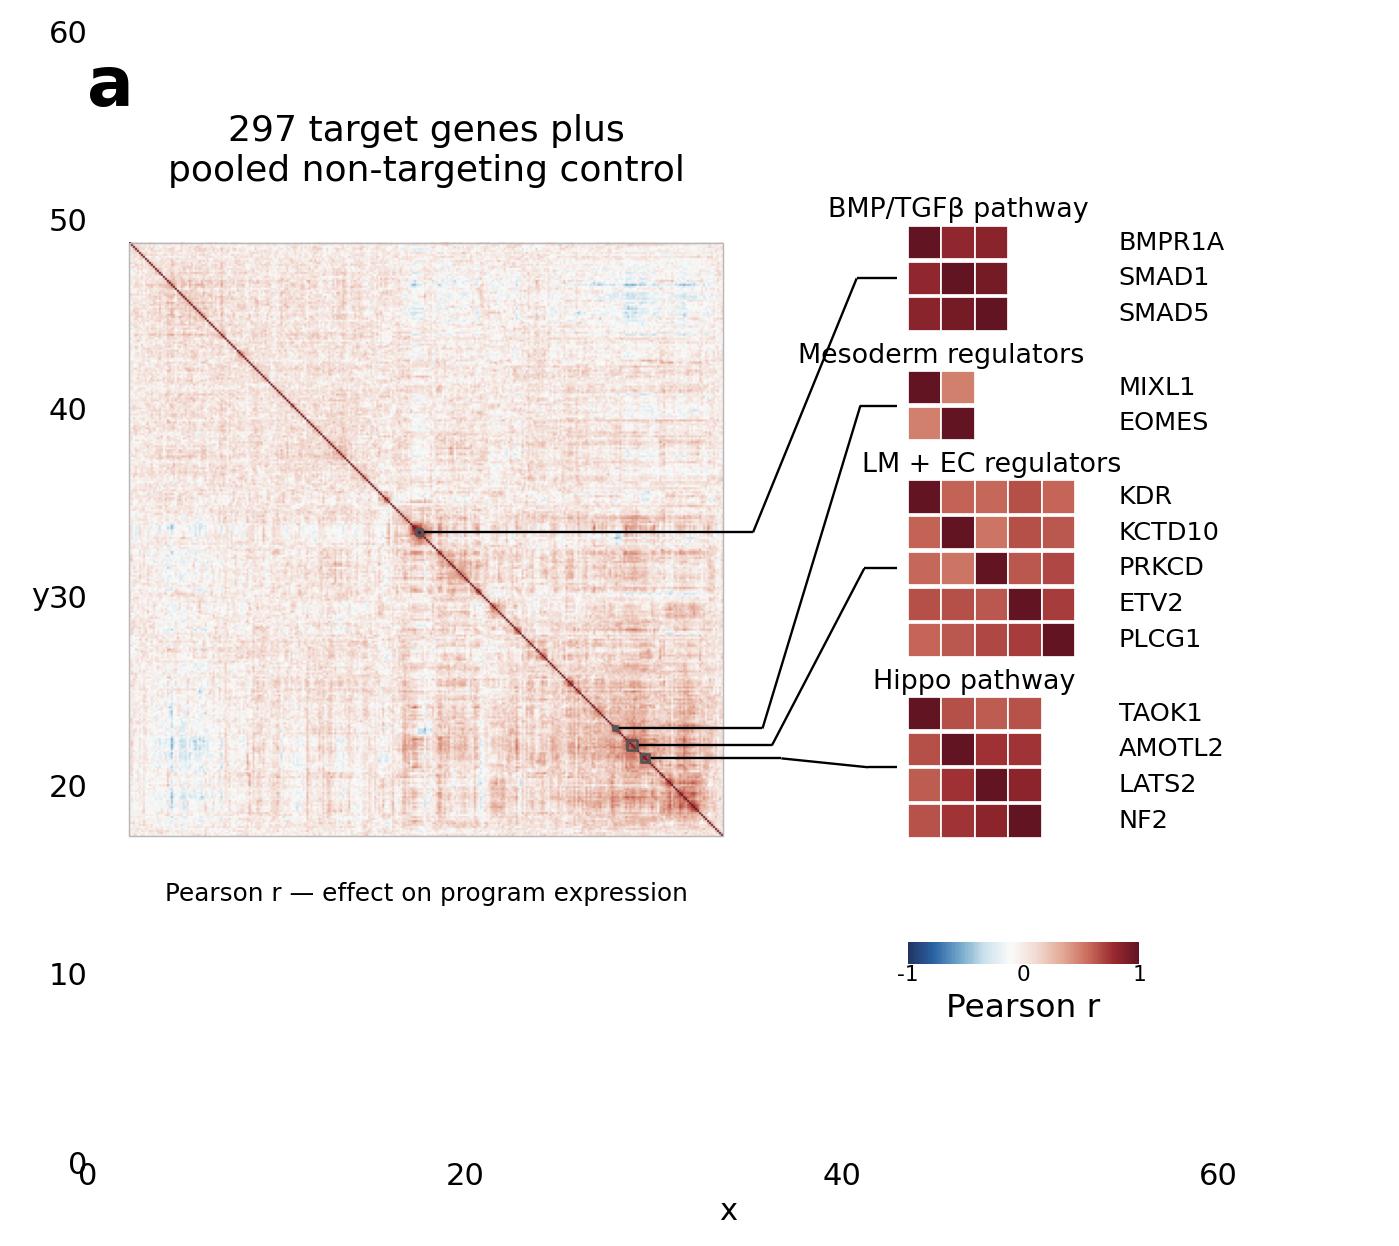

In [3]:
plot_a, corr_a, order_a, inset_a, boxes_a = plot_figure2a(effect_matrix)
out = panel_directory(ctx, "a")
outputs = export_plotnine(
    plot_a,
    "a",
    "Figure_02a_perturbation_effect_correlation",
)
corr_a.to_csv(out / "Figure_02a_target_correlation.csv")
order_a.to_csv(out / "Figure_02a_clustered_target_order.csv", index=False)
inset_a.to_csv(out / "Figure_02a_selected_group_correlations.csv", index=False)
boxes_a.to_csv(out / "Figure_02a_cluster_boxes.csv", index=False)
write_receipt(
    ctx,
    "a",
    status="SOURCE_VERIFIED_IMPLEMENTATION",
    inputs={"workbook": str(workbook), "sha256": EXPECTED_SHA},
    outputs=outputs,
    parameters={
        "profiles": "297 targets plus pooled control",
        "features": 200,
        "distance": "1-Pearson r",
        "linkage": "average, optimal ordering",
        "plotting_backend": "plotnine",
    },
)
display(plot_a)


## Panel b — program effects and Day 3 EC output

The EC-output column uses all 120 controls. Target-guide percentages exclude cells carrying any control guide; each control-guide percentage excludes cells carrying the evaluated target. Two-sided Welch P values are BH-adjusted across all 297 targets.


findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberati

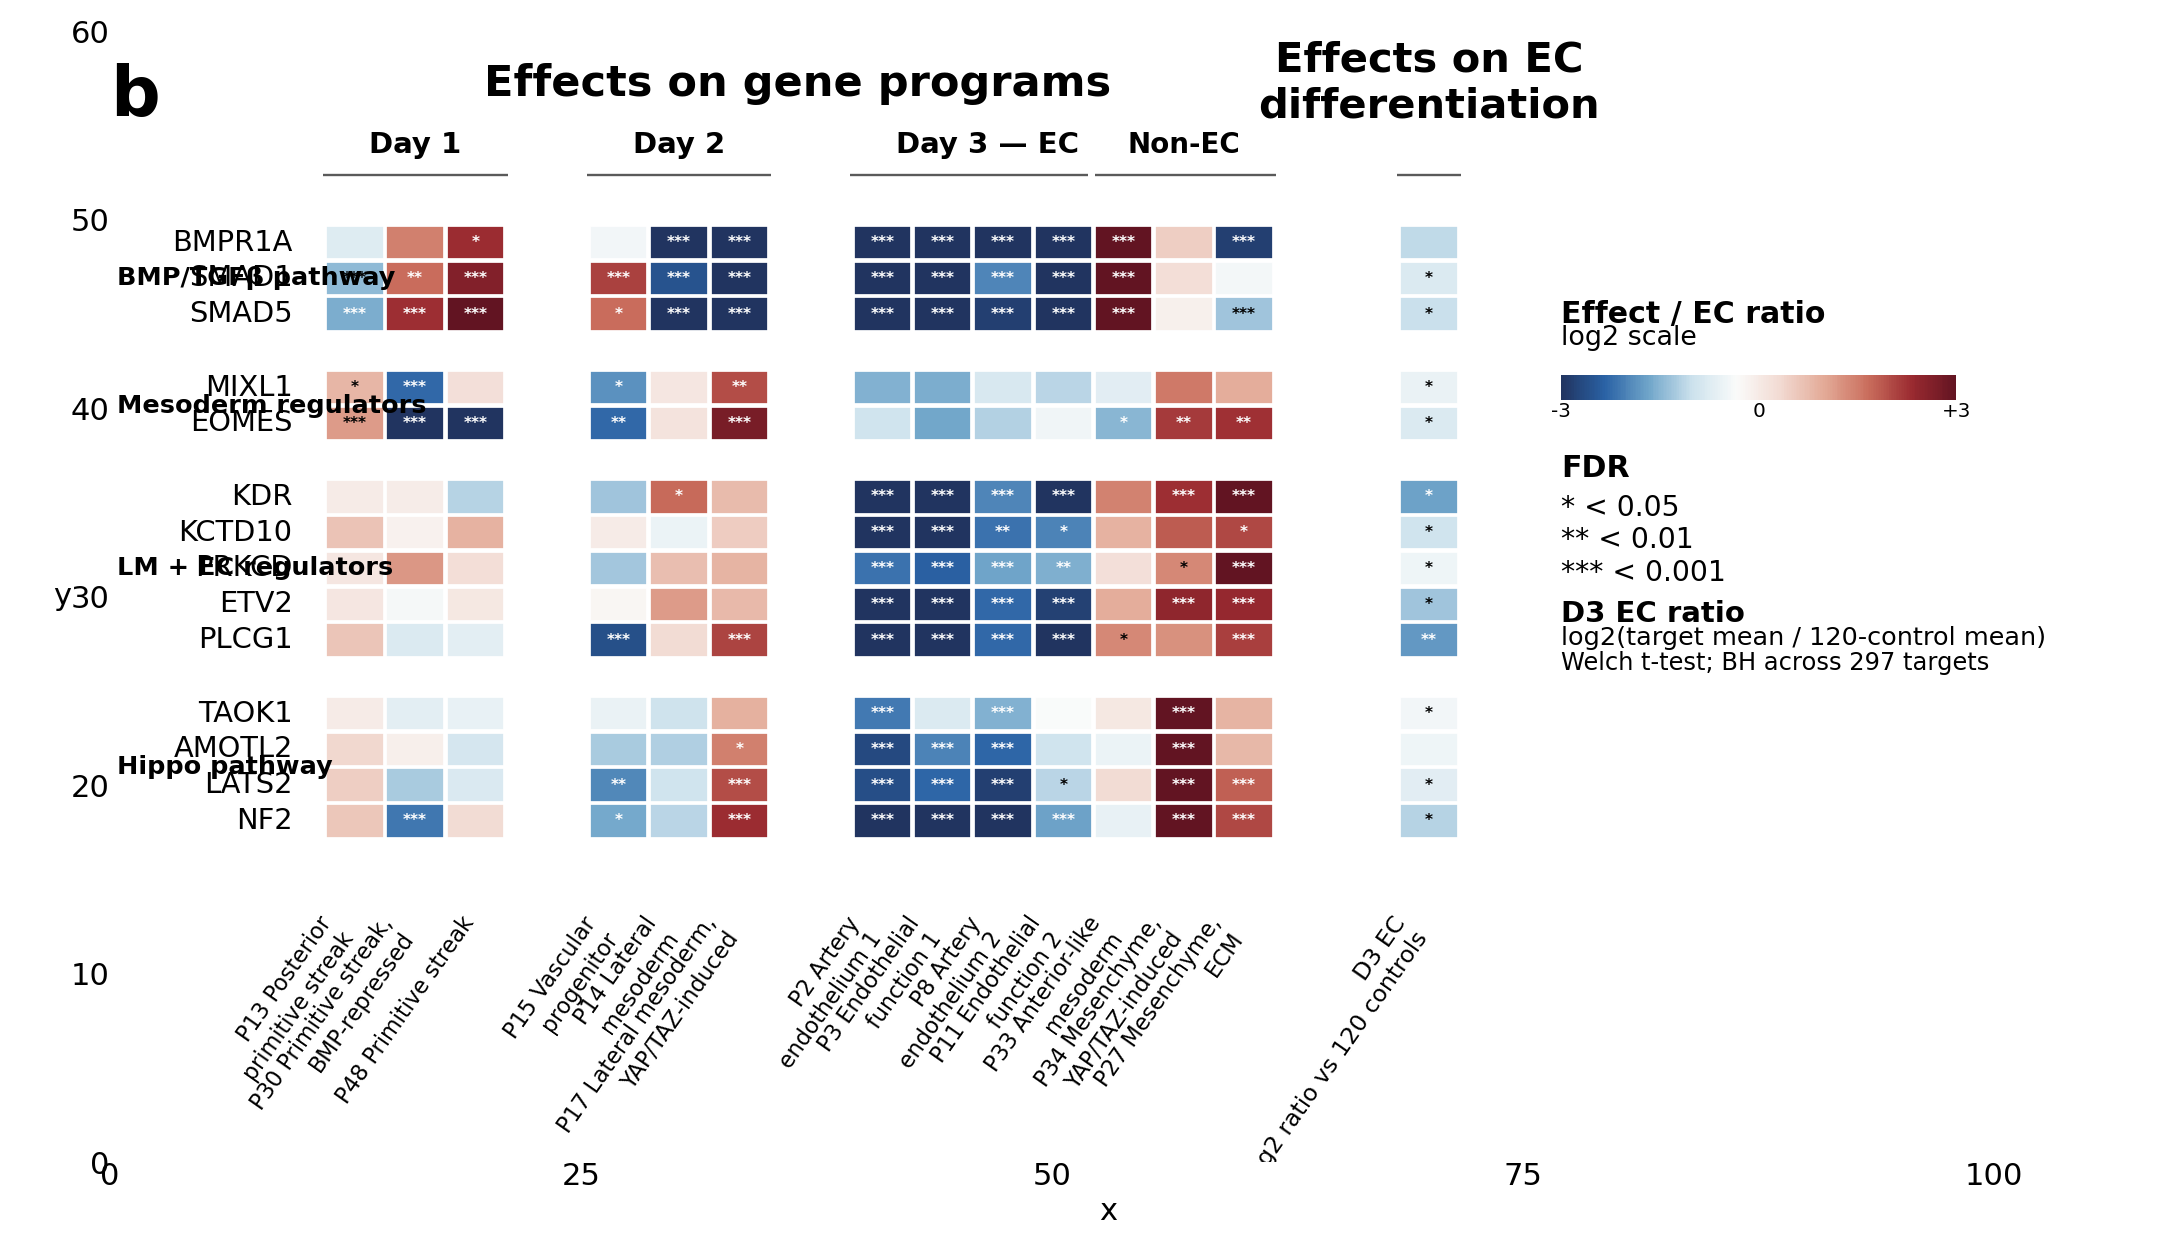

,mean_target_EC_pct,mean_control_EC_pct,welch_pvalue_two_sided,FDR_BH_297_genes,significance
gene,,,,,
BMPR1A,24.965411,53.070242,0.021312,0.094082,
SMAD1,31.068073,53.805142,0.000502,0.013779,*
SMAD5,26.621488,54.117266,0.000245,0.012130,*
MIXL1,35.400866,52.819741,0.002596,0.028244,*
EOMES,30.259856,52.309024,0.004393,0.035265,*
KDR,16.095768,52.863341,0.002932,0.028244,*
KCTD10,27.395501,52.679444,0.004572,0.035732,*
PRKCD,37.550783,53.308899,0.001674,0.026139,*
ETV2,21.111272,53.265735,0.000296,0.012314,*


In [4]:
guide_b, stats_b, meta_b = compute_figure2b_ec_statistics(
    adata,
    guide_metadata_path,
)
plot_b, effects_b, fdr_b, program_source_b, ec_source_b = plot_figure2b(
    selected_associations,
    stats_b,
)
out = panel_directory(ctx, "b")
outputs = export_plotnine(
    plot_b,
    "b",
    "Figure_02b_selected_program_and_EC_effects",
)
effects_b.to_csv(out / "Figure_02b_effect_matrix.csv")
fdr_b.to_csv(out / "Figure_02b_FDR_matrix.csv")
program_source_b.to_csv(
    out / "Figure_02b_program_effect_source.csv",
    index=False,
)
stats_b.to_csv(
    out / "Figure_02b_Welch_EC_statistics_all_297_genes.csv",
    index=False,
)
guide_b.to_csv(
    out / "Figure_02b_guide_level_D3_EC_percentages_all_297_genes.csv.gz",
    index=False,
    compression="gzip",
)
write_receipt(
    ctx,
    "b",
    status="SOURCE_VERIFIED_METHOD_IMPLEMENTATION",
    inputs={
        "workbook": str(workbook),
        "anndata": str(adata_path),
        "guide_metadata": str(guide_metadata_path),
    },
    outputs=outputs,
    parameters={
        "control_guides": "60 non-targeting + 60 safe-targeting",
        "target_exclusion": "any control guide",
        "control_exclusion": "evaluated target",
        "test": "two-sided Welch t-test",
        "BH_tests": 297,
        "effect": "log2(target/control)",
        "plotting_backend": "plotnine",
        **meta_b,
    },
)
display(plot_b)
stats_b.set_index("gene").loc[
    [gene for genes in FIGURE2_TARGET_GROUPS.values() for gene in genes],
    [
        "mean_target_EC_pct",
        "mean_control_EC_pct",
        "welch_pvalue_two_sided",
        "FDR_BH_297_genes",
        "significance",
    ],
]


## Panel d — guide-level Day 3 EC differentiation

The control box combines all **120 negative-control guides**: 60 non-targeting and 60 safe-targeting guides. For each individual control guide, cells also carrying any guide targeting KDR, PLCG1, PRKCD, or ETV2 are excluded. Each of the four targeting-guide distributions is compared with the resulting 120-guide control distribution using a two-sided Welch t-test; P values are BH-adjusted across the four displayed genes.


findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberati

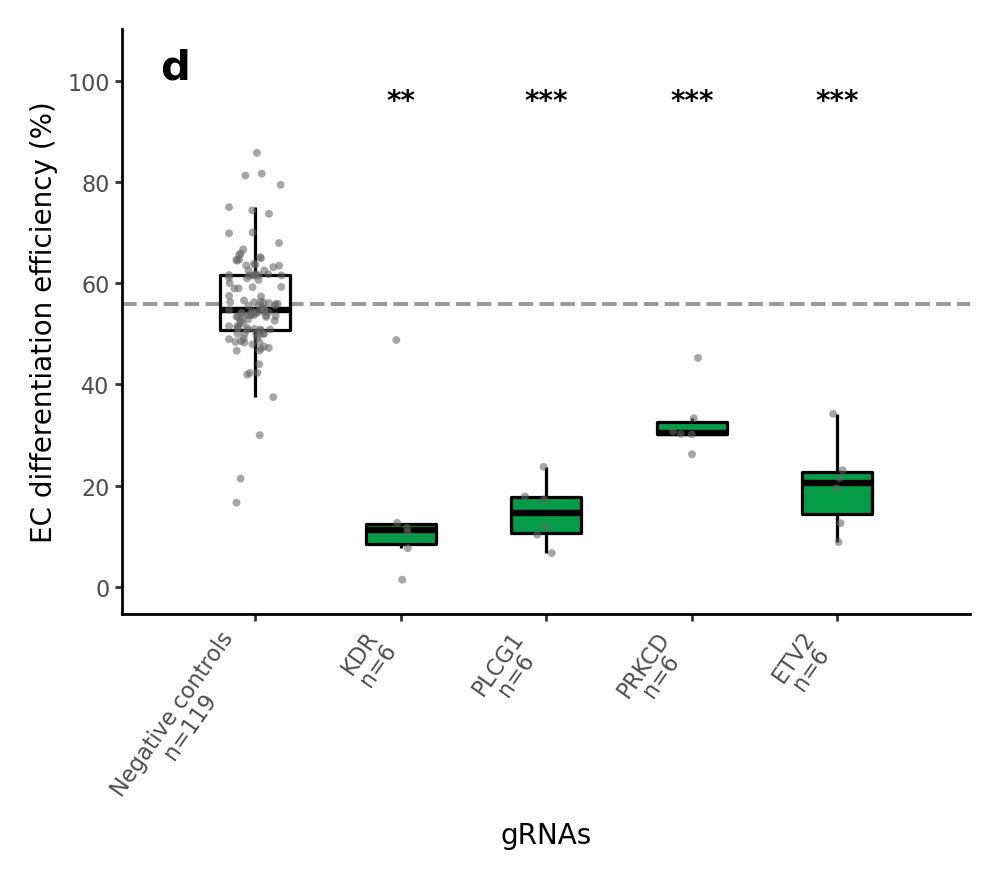

,gene,n_targeting_guides,n_control_guides,n_non_targeting_guides_designed,n_safe_targeting_guides_designed,mean_target_EC_pct,median_target_EC_pct,sd_target_EC_pct,mean_control_EC_pct,median_control_EC_pct,sd_control_EC_pct,difference_target_minus_control_pp,effect_log2_target_over_control,welch_t_statistic,welch_df,welch_pvalue_two_sided,FDR_BH,significance,BH_number_tests
0,KDR,6,119,60,60,15.534430,11.287758,16.789636,55.888527,54.625551,9.941071,-40.354098,-1.847083,-5.836026,5.178255,0.001857,0.001857,**,4
1,PLCG1,6,119,60,60,14.656260,14.617149,6.148682,55.888527,54.625551,9.941071,-41.232268,-1.931035,-15.439970,6.400115,0.000003,0.000011,***,4
2,PRKCD,6,119,60,60,32.652519,30.477725,6.571362,55.888527,54.625551,9.941071,-23.236008,-0.775358,-8.201038,6.216942,0.000147,0.000196,***,4
3,ETV2,6,119,60,60,19.969901,20.510856,8.851083,55.888527,54.625551,9.941071,-35.918626,-1.484725,-9.638493,5.655288,0.000101,0.000196,***,4


In [5]:
guide_d, stats_d, meta_d = compute_figure2d_guide_ec_120_controls(
    adata,
    guide_metadata_path,
    FIGURE2D_TARGETS,
    control_exclusion_targets=FIGURE2D_TARGETS,
)
plot_d, jitter_d = plot_figure2d_120_controls(guide_d, stats_d)
out = panel_directory(ctx, "d")
outputs = export_plotnine(
    plot_d,
    "d",
    "Figure_02d_guide_level_D3_EC_fraction",
)
guide_d.to_csv(
    out / "Figure_02d_guide_level_D3_EC_percentages.csv",
    index=False,
)
stats_d.to_csv(out / "Figure_02d_Welch_statistics.csv", index=False)
jitter_d.to_csv(
    out / "Figure_02d_plot_jitter_coordinates.csv",
    index=False,
)
write_receipt(
    ctx,
    "d",
    status="SOURCE_VERIFIED_METHOD_IMPLEMENTATION",
    inputs={
        "anndata": str(adata_path),
        "guide_metadata": str(guide_metadata_path),
    },
    outputs=outputs,
    parameters={
        "targets": FIGURE2D_TARGETS,
        "control": "120 guides: 60 non-targeting + 60 safe-targeting",
        "control_exclusion_targets": FIGURE2D_TARGETS,
        "targeting_guide_exclusion": "none beyond D3 restriction",
        "test": "two-sided Welch t-test",
        "BH_tests": 4,
        "plotting_backend": "plotnine",
        **meta_d,
    },
)
display(plot_d)
stats_d


## Panel e — P17/P27 and marker UMAPs

P17, SLC8A1, P27, and GATA4 are rendered with the recovered plotnine UMAP implementation and its original `YlGnBu` color scale, light-gray background, and feature-specific 99th-percentile maxima.


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

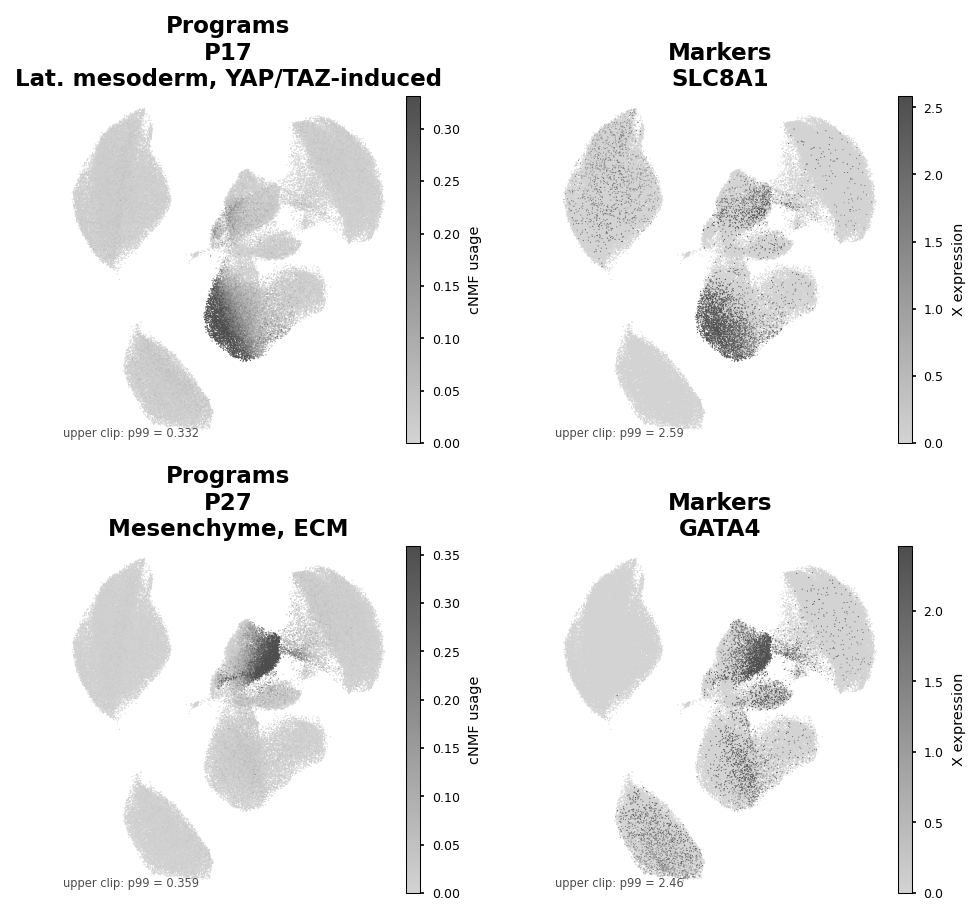

In [6]:
plot_e, source_e = plot_figure2e_umaps(adata, usage)
out = panel_directory(ctx, "e")
outputs = export_plotnine(
    plot_e,
    "e",
    "Figure_02e_P17_P27_SLC8A1_GATA4_umaps",
)
source_paths = {}
for name, table in source_e.items():
    path = out / f"Figure_02e_{name}_source.csv.gz"
    table.to_csv(path, compression="gzip")
    source_paths[name] = str(path)
write_receipt(
    ctx,
    "e",
    status="SOURCE_STYLE_RECOVERED",
    inputs={"anndata": str(adata_path), "usage": str(usage_path)},
    outputs={**outputs, **source_paths},
    parameters={
        "features": ["P17", "SLC8A1", "P27", "GATA4"],
        "cmap": "YlGnBu",
        "vmax": "feature-specific p99",
        "plotting_backend": "plotnine",
    },
)
display(plot_e)


## Panel f — carrier-seeded neighborhood enrichment

This is a direct port of `fig3_carrierseeded_neighborhood_panels_interactive_plotnine_style.ipynb`, not a new renderer. It uses all target carriers as seeds, all 120 pooled non-targeting/safe-targeting control guides, same-day 300-neighbor Euclidean neighborhoods in z-scored 50-program cNMF space, a 0.5 pseudocount, and the recovered red/white/blue plotnine faceted UMAP style.


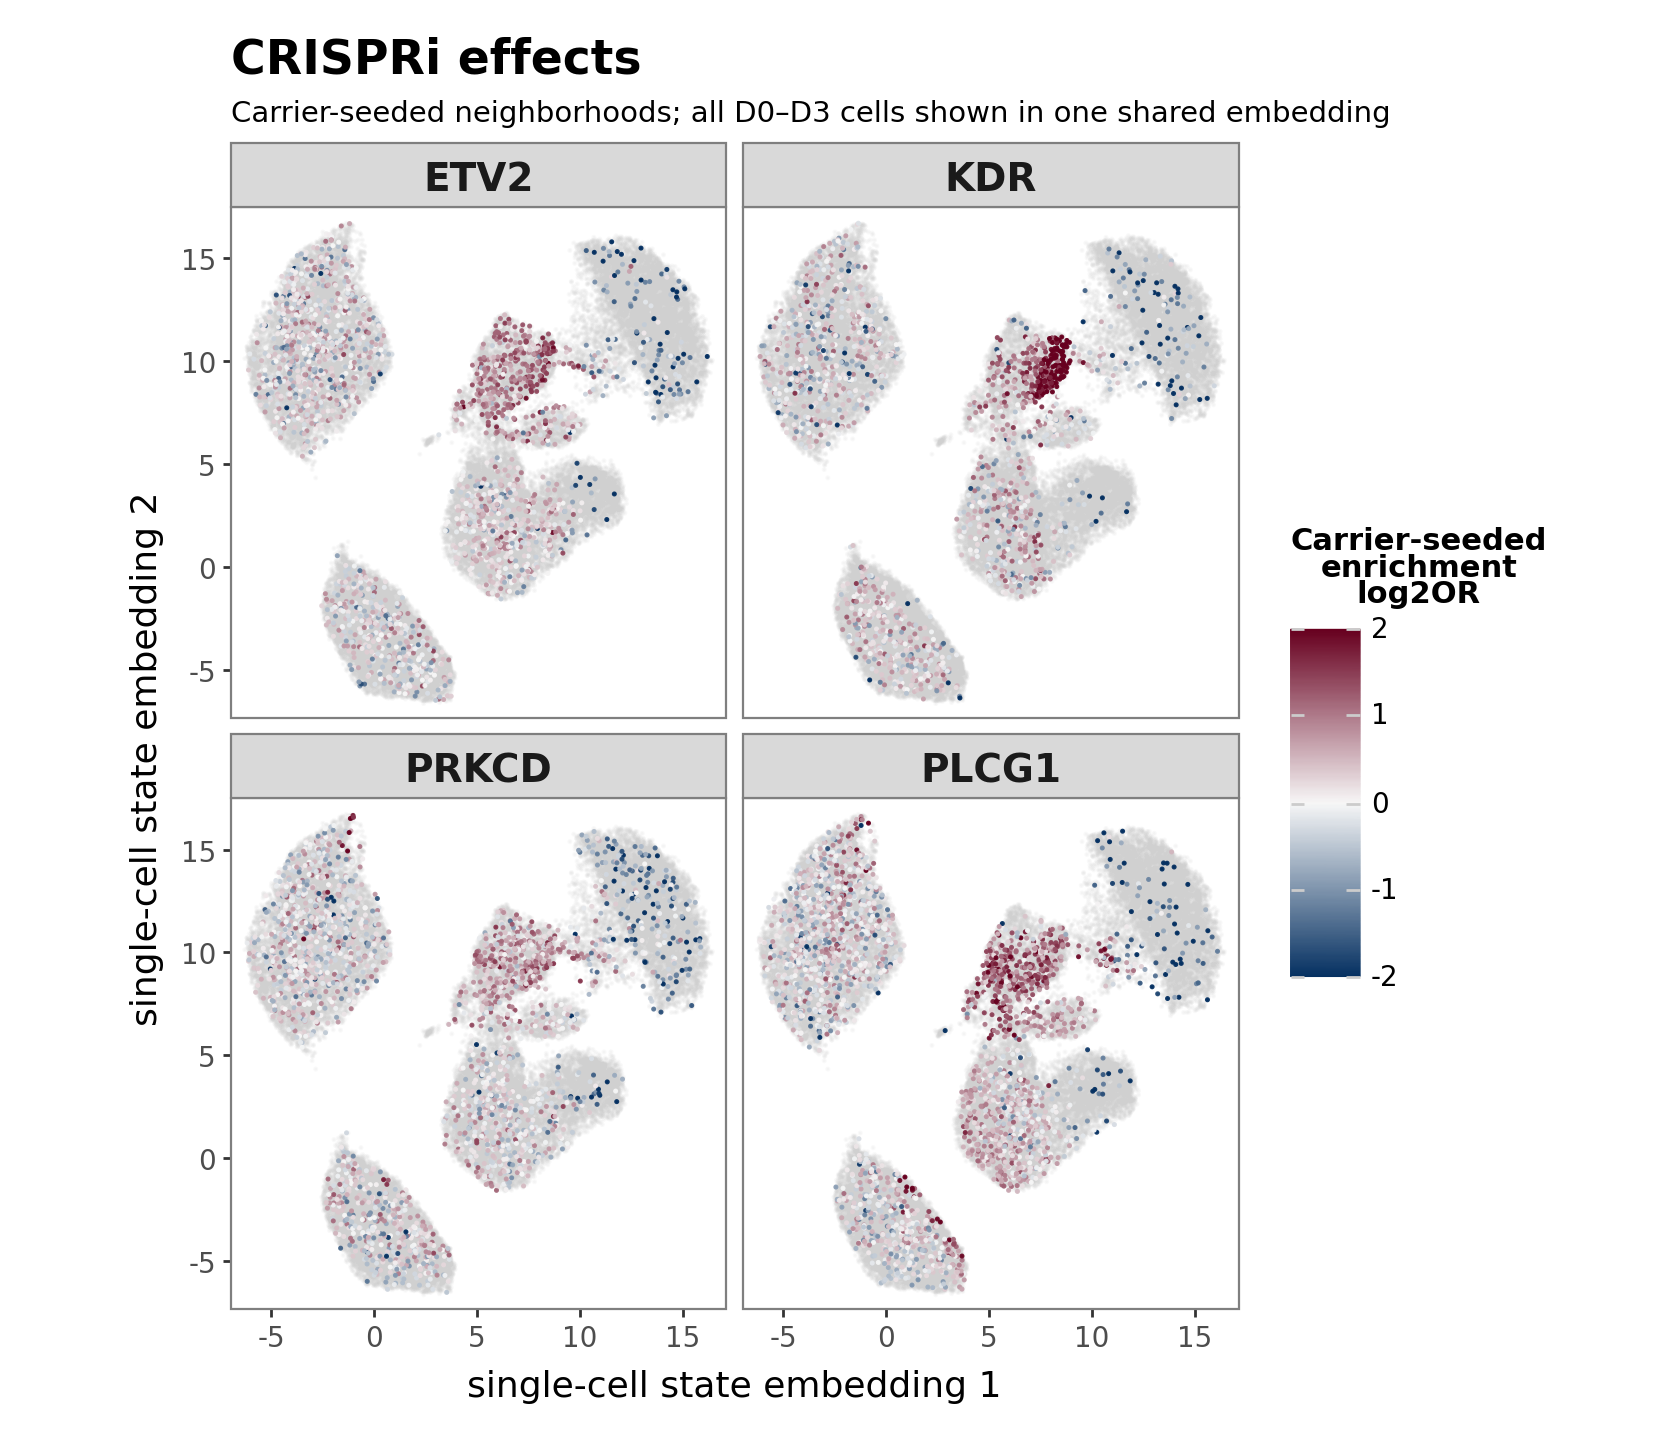

In [7]:
scores_f, background_f = compute_figure2f_carrier_seeded(
    adata,
    usage,
    guide_metadata_path,
    targets=FIGURE2F_TARGETS,
    k=300,
    pseudocount=0.5,
)
plot_f, scores_plot_f, background_plot_f = plot_figure2f(
    scores_f,
    background_f,
    targets=FIGURE2F_TARGETS,
)
out = panel_directory(ctx, "f")
outputs = export_plotnine(
    plot_f,
    "f",
    "Figure_02f_carrier_seeded_neighborhoods_plotnine",
)
scores_f.to_csv(
    out / "Figure_02f_carrier_seeded_neighborhood_statistics.csv",
    index=False,
)
scores_plot_f.to_csv(
    out / "Figure_02f_plotting_seed_cells.csv",
    index=False,
)
background_plot_f.to_csv(
    out / "Figure_02f_sampled_background_cells.csv",
    index=False,
)
write_receipt(
    ctx,
    "f",
    status="SOURCE_RECOVERED_IMPLEMENTATION_PENDING_SHERLOCK_EXECUTION",
    inputs={
        "anndata": str(adata_path),
        "usage": str(usage_path),
        "guide_metadata": str(guide_metadata_path),
    },
    outputs=outputs,
    parameters={
        "source_notebook": (
            "programDE/notebooks/fig3_carrierseeded_neighborhood_"
            "plotnine_style_notebook_package/"
            "fig3_carrierseeded_neighborhood_panels_interactive_"
            "plotnine_style.ipynb"
        ),
        "targets": FIGURE2F_TARGETS,
        "mode": "all_carriers",
        "control_guides": "60 non-targeting + 60 safe-targeting",
        "k": 300,
        "distance": "Euclidean on z-scored 50-program usage",
        "same_day_neighbors": True,
        "same_day_baseline": True,
        "pseudocount": 0.5,
        "plotting_backend": "plotnine",
        "plot_style": "simple_color",
        "color_scale": {
            "low": "#053061",
            "mid": "#F7F7F7",
            "high": "#67001F",
            "limits": [-2, 2],
        },
    },
)
display(plot_f)
